<a href="https://colab.research.google.com/github/vprathik192-code/big_data_analysis_MSFT_5757361/blob/main/fofpython.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%pip install numpy pandas matplotlib

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the selected CSV file
file_path = '/content/crsp_monthly_workshop.csv'
df = pd.read_csv(file_path)

# Display the first few rows to confirm it loaded correctly
display(df.head())

,permno,date,tsymbol,comnam,prc,ret,vol,shrout
0,11308,2009-12-31,KO,COCA COLA CO,57.00,-0.003497,1928924.0,2317181.0
1,11308,2010-01-29,KO,COCA COLA CO,54.25,-0.048246,1927039.0,2317181.0
2,11308,2010-02-26,KO,COCA COLA CO,52.72,-0.028203,2290196.0,2305124.0
3,11308,2010-03-31,KO,COCA COLA CO,55.00,0.051593,2678707.0,2305124.0
4,11308,2010-04-30,KO,COCA COLA CO,53.45,-0.028182,2219286.0,2307051.0


In [9]:
# Export the DataFrame back to a new CSV file (e.g., exported_crsp_workshop.csv)
export_path = '/content/exported_crsp_workshop.csv'
df.to_csv(export_path, index=False)
print(f"File successfully exported to: {export_path}")

File successfully exported to: /content/exported_crsp_workshop.csv


### Task 1 (d): Identify the Companies in the Dataset
We will find the unique companies in our dataset using the `comnam` column.

In [10]:
# Identify unique companies in the dataset
unique_companies = df['comnam'].dropna().unique()
print("Companies in the dataset:")
for company in unique_companies:
    print(f"- {company}")

Companies in the dataset:
- COCA COLA CO
- APPLE INC
- BOEING CO
- STEEL DYNAMICS INC
- NVIDIA CORP


### Convert 'date' Column to Datetime
Let's convert the `date` column into standard Python `datetime` objects to make time-based indexing and analysis easier.

In [11]:
print("Data type before conversion:", df['date'].dtypes)

# Convert the 'date' column to datetime format
df['date'] = pd.to_datetime(df['date'])

print("Data type after conversion:", df['date'].dtypes)
display(df.head())

Data type before conversion: object
Data type after conversion: datetime64[ns]


,permno,date,tsymbol,comnam,prc,ret,vol,shrout
0,11308,2009-12-31,KO,COCA COLA CO,57.00,-0.003497,1928924.0,2317181.0
1,11308,2010-01-29,KO,COCA COLA CO,54.25,-0.048246,1927039.0,2317181.0
2,11308,2010-02-26,KO,COCA COLA CO,52.72,-0.028203,2290196.0,2305124.0
3,11308,2010-03-31,KO,COCA COLA CO,55.00,0.051593,2678707.0,2305124.0
4,11308,2010-04-30,KO,COCA COLA CO,53.45,-0.028182,2219286.0,2307051.0


### Clean Price (`prc`) and Return (`ret`) Columns
- In CRSP data, negative prices usually represent bid/ask averages. We will take the absolute value to get the correct price.
- We will ensure returns (`ret`) are stored as numeric values, converting any invalid values (such as text placeholders) to NaN (Not a Number).

In [12]:
# Take the absolute value of the price column to clean negative values
df['prc_cleaned'] = df['prc'].abs()

# Convert returns to numeric, coercing any errors (e.g., text placeholders) to NaN
df['ret_cleaned'] = pd.to_numeric(df['ret'], errors='coerce')

# Display summary showing the impact of cleaning
print("Data cleaning complete!")
display(df[['prc', 'prc_cleaned', 'ret', 'ret_cleaned']].describe())

Data cleaning complete!


,prc,prc_cleaned,ret,ret_cleaned
count,907.000000,907.000000,907.000000,907.000000
mean,136.398403,136.398403,0.021382,0.021382
std,142.425976,142.425976,0.096962,0.096962
min,9.190000,9.190000,-0.457890,-0.457890
25%,40.850000,40.850000,-0.031019,-0.031019
50%,80.800000,80.800000,0.019951,0.019951
75%,179.895000,179.895000,0.068266,0.068266
max,1096.329960,1096.329960,0.553247,0.553247


### Compute Market Capitalization
Market capitalization is calculated as:
$$\text{Market Capitalization} = \text{Price} \times \text{Shares Outstanding}$$
In CRSP, the `shrout` column represents shares outstanding (usually in thousands). Let's calculate the market capitalization using our cleaned price column (`prc_cleaned`).

In [13]:
# Calculate market capitalization
df['mcap'] = df['prc_cleaned'] * df['shrout']

# Display the updated data frame focusing on the new column
display(df[['comnam', 'date', 'prc_cleaned', 'shrout', 'mcap']].head())

,comnam,date,prc_cleaned,shrout,mcap
0,COCA COLA CO,2009-12-31,57.00,2317181.0,1.320793e+08
1,COCA COLA CO,2010-01-29,54.25,2317181.0,1.257071e+08
2,COCA COLA CO,2010-02-26,52.72,2305124.0,1.215261e+08
3,COCA COLA CO,2010-03-31,55.00,2305124.0,1.267818e+08
4,COCA COLA CO,2010-04-30,53.45,2307051.0,1.233119e+08


### Plot Time Series Chart for Each Company
We will now visualize the time series of the cleaned stock price (`prc_cleaned`) for each company in our dataset to observe their trends over time.

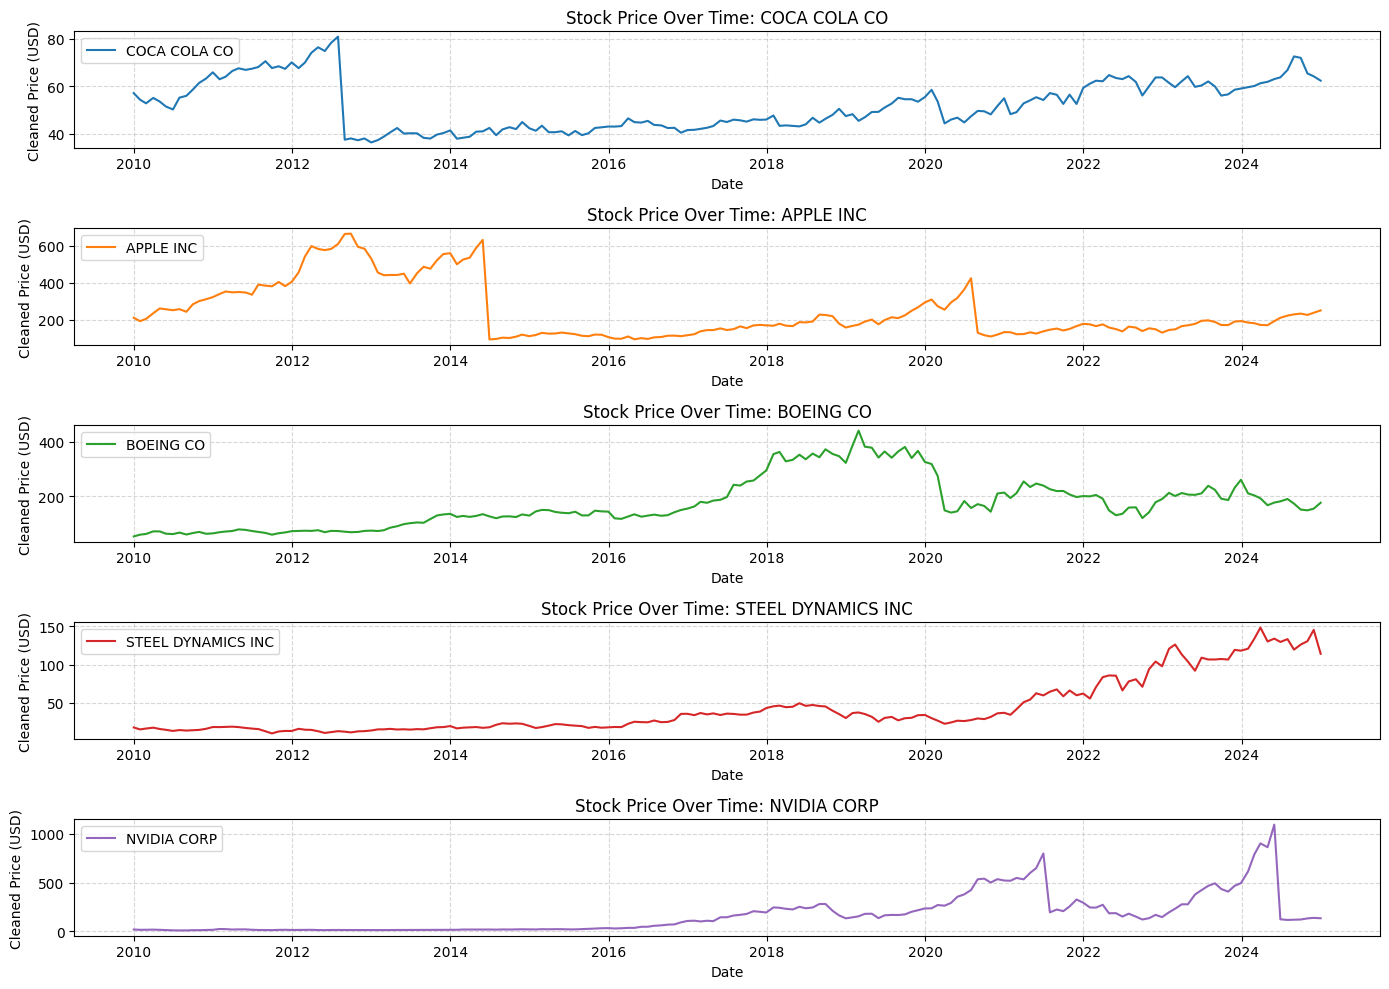

In [14]:
import matplotlib.pyplot as plt

# Get the list of unique companies
companies = df['comnam'].dropna().unique()

# Create a plot for each company
plt.figure(figsize=(14, 10))

for i, company in enumerate(companies, 1):
    # Filter data for the specific company and sort by date
    company_df = df[df['comnam'] == company].sort_values('date')

    plt.subplot(len(companies), 1, i)
    plt.plot(company_df['date'], company_df['prc_cleaned'], label=company, color=f'C{i-1}')
    plt.title(f"Stock Price Over Time: {company}")
    plt.xlabel("Date")
    plt.ylabel("Cleaned Price (USD)")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

### Merged Stock Price Comparison
To make comparing the companies easier, we will plot all of their cleaned price trends on a single, unified chart.

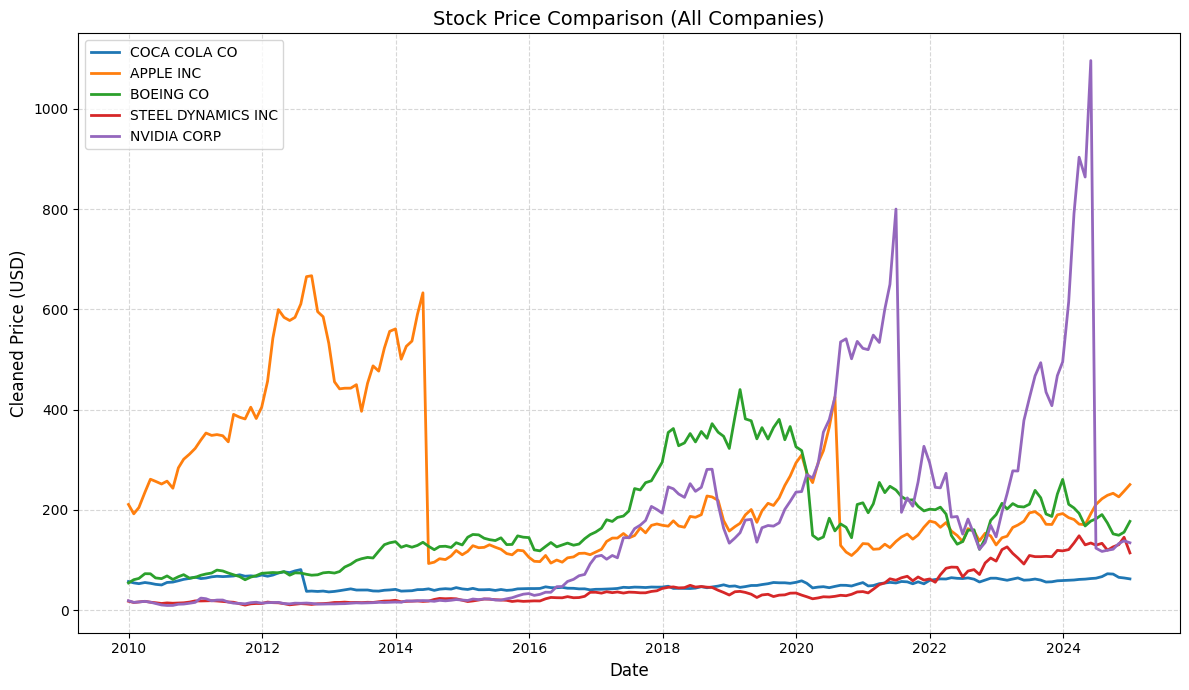

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

# Plot each company on the same axes
for company in companies:
    company_df = df[df['comnam'] == company].sort_values('date')
    plt.plot(company_df['date'], company_df['prc_cleaned'], label=company, linewidth=2)

plt.title("Stock Price Comparison (All Companies)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Cleaned Price (USD)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

### Market Capitalization Comparison Over Time
We will now plot the market capitalization (`mcap`) for each company on a single time series graph to compare their overall market valuation sizes.

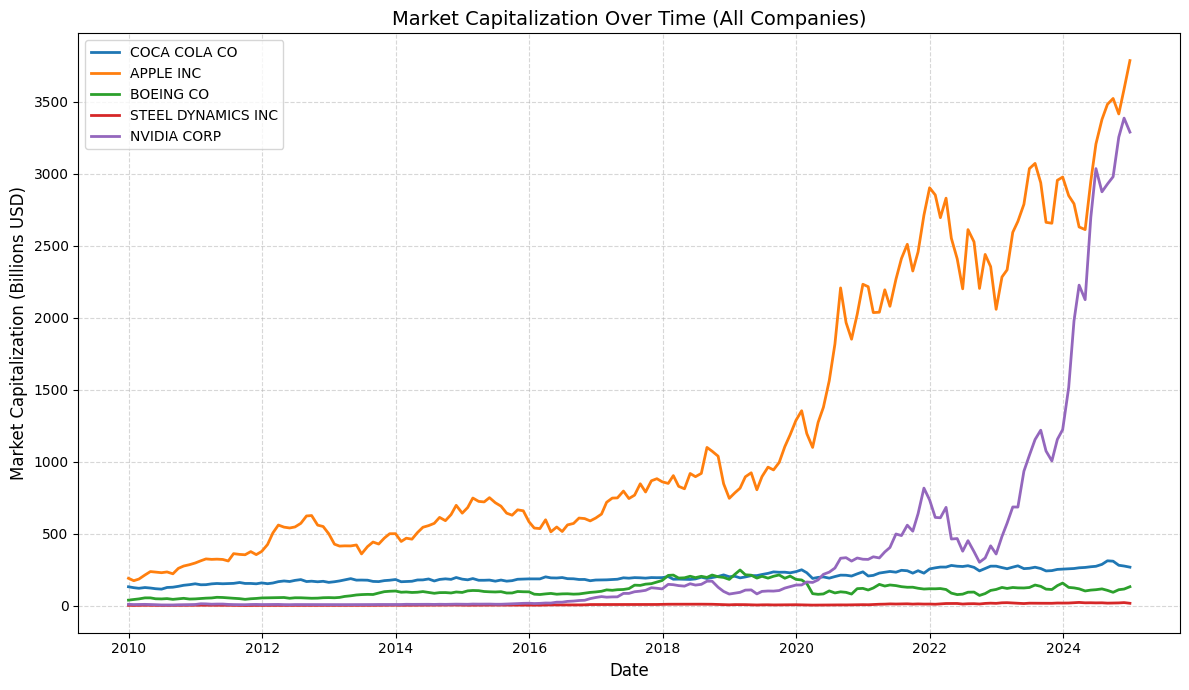

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

# Plot the market capitalization over time for each company
for company in companies:
    company_df = df[df['comnam'] == company].sort_values('date')
    # We divide by 1e9 to show the market cap in billions of dollars for better readability
    plt.plot(company_df['date'], company_df['mcap'] / 1e6, label=company, linewidth=2)

plt.title("Market Capitalization Over Time (All Companies)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Market Capitalization (Billions USD)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

### Monthly Returns Comparison Over Time
We will now plot the cleaned monthly returns (`ret_cleaned`) for each company on a single time series graph to compare their performance and volatility.

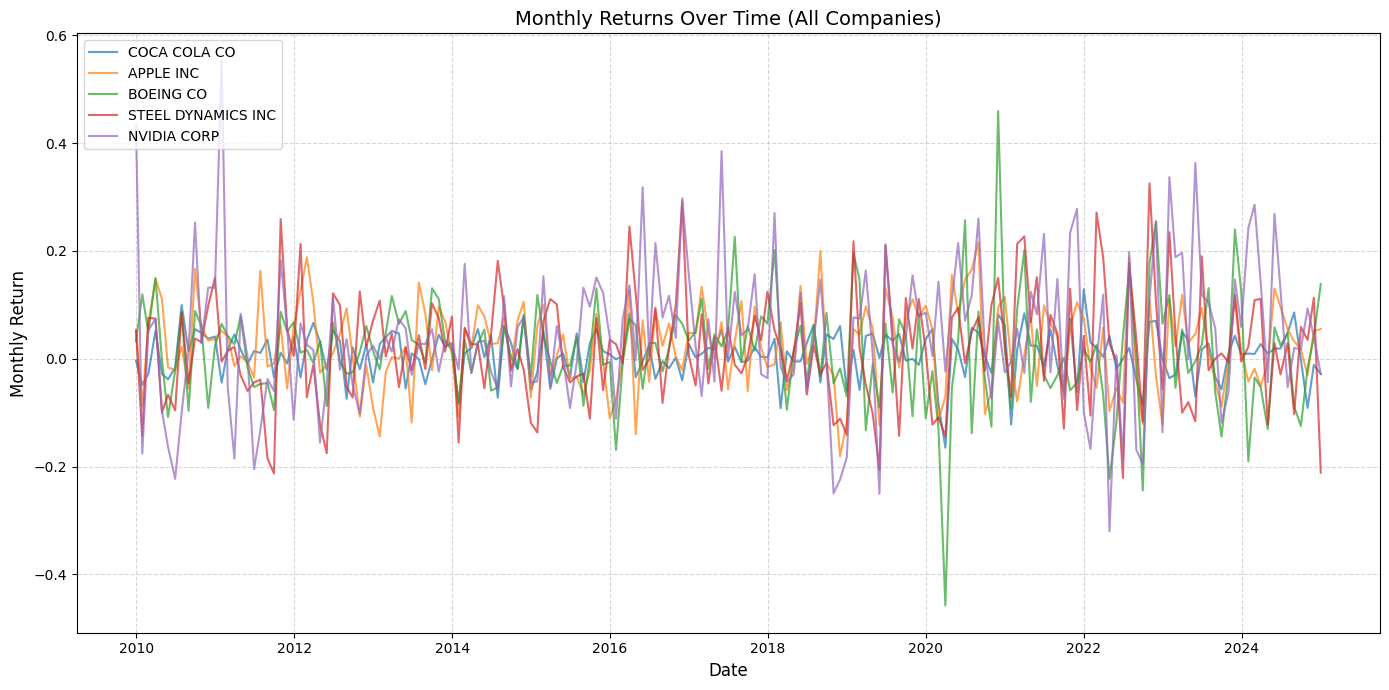

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

# Plot monthly returns over time for each company
for company in companies:
    company_df = df[df['comnam'] == company].sort_values('date')
    plt.plot(company_df['date'], company_df['ret_cleaned'], label=company, linewidth=1.5, alpha=0.7)

plt.title("Monthly Returns Over Time (All Companies)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Monthly Return", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

### Compute Cumulative Returns (Gross and Net)
To find the cumulative returns over time for each company, we will:
1. Sort the data by date for each company.
2. Compute the monthly gross return multiplier: $1 + R_t$ (using `ret_cleaned`).
3. Calculate the cumulative product of these multipliers to get the **Gross Cumulative Return**.
4. Subtract 1 from the gross cumulative return to get the **Net Cumulative Return**.

In [18]:
# Sort the dataframe chronologically to ensure the cumulative product is calculated in order
df = df.sort_values(by=['comnam', 'date']).reset_index(drop=True)

# Fill missing returns with 0 so they do not break the cumulative product
df['ret_filled'] = df['ret_cleaned'].fillna(0)

# Calculate Gross Return (1 + R)
df['gross_ret_monthly'] = 1 + df['ret_filled']

# Group by company and calculate cumulative product for Gross Cumulative Return
df['cum_gross_ret'] = df.groupby('comnam')['gross_ret_monthly'].cumprod()

# Calculate Net Cumulative Return (Gross Cumulative Return - 1)
df['cum_net_ret'] = df['cum_gross_ret'] - 1

# Display the final cumulative returns for each company
print("Cumulative Returns Calculation Complete!")
final_returns = df.groupby('comnam').last()[['date', 'cum_gross_ret', 'cum_net_ret']].reset_index()
display(final_returns)

Cumulative Returns Calculation Complete!


,comnam,date,cum_gross_ret,cum_net_ret
0,APPLE INC,2024-12-31,50.429517,49.429517
1,BOEING CO,2024-12-31,4.337062,3.337062
2,COCA COLA CO,2024-12-31,3.452706,2.452706
3,NVIDIA CORP,2024-12-31,504.975853,503.975853
4,STEEL DYNAMICS INC,2024-12-31,9.576715,8.576715


### Cumulative Returns Comparison Over Time
We will now plot the cumulative net returns (`cum_net_ret`) for each company on a single time series graph to compare their long-term growth and performance starting from our base date.

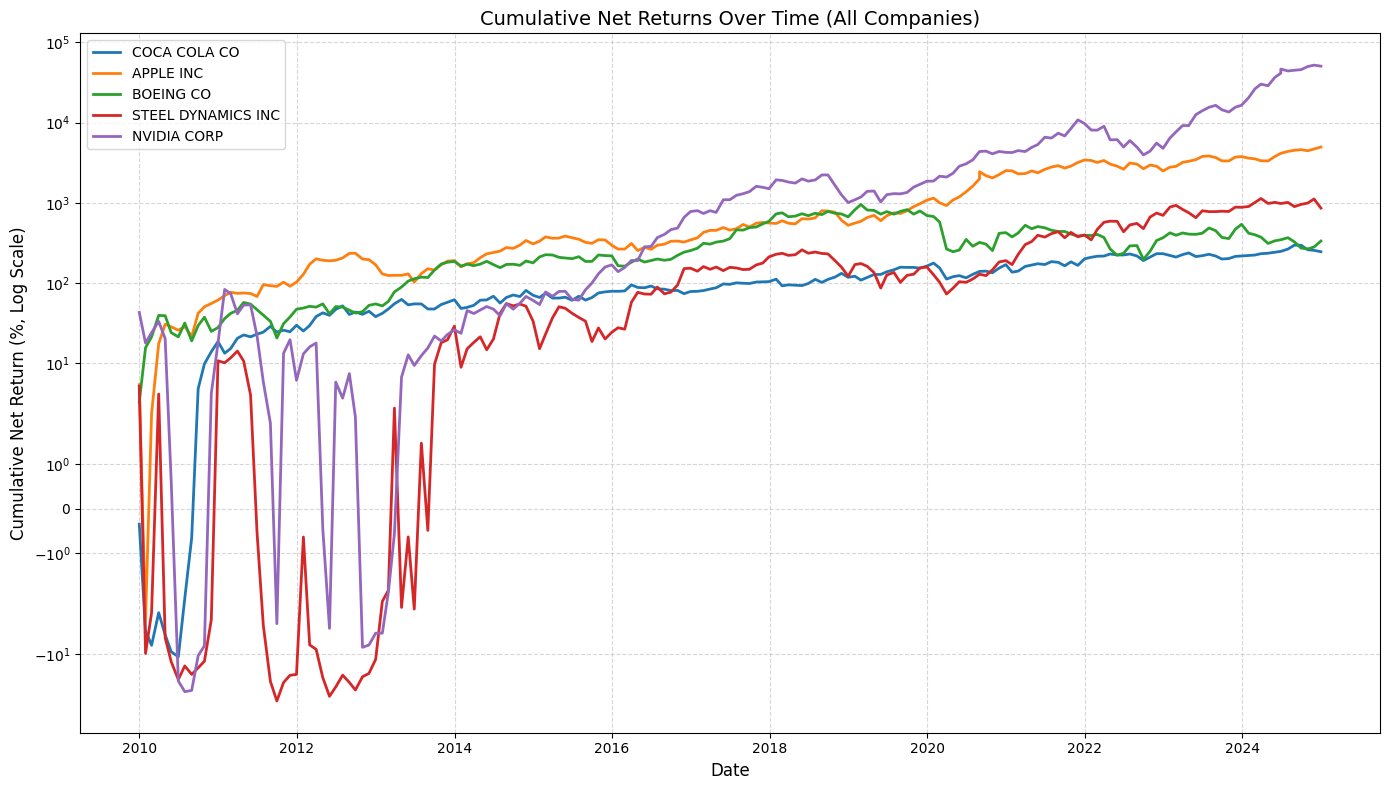

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

# Plot cumulative net returns over time for each company
for company in companies:
    company_df = df[df['comnam'] == company].sort_values('date')
    # Convert net return to percentage (e.g., 1.0 = 100% return)
    plt.plot(company_df['date'], company_df['cum_net_ret'] * 100, label=company, linewidth=2)

plt.title("Cumulative Net Returns Over Time (All Companies)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Cumulative Net Return (%)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)

# Displaying with a log scale on the y-axis because Nvidia's returns are significantly higher than others
plt.yscale('symlog')
plt.ylabel("Cumulative Net Return (%, Log Scale)", fontsize=12)

plt.tight_layout()
plt.show()

### Cumulative Gross Returns Comparison Over Time
We will now plot the cumulative gross returns (`cum_gross_ret`) for each company. This metric represents the growth of $1 invested in each of the stocks over time.

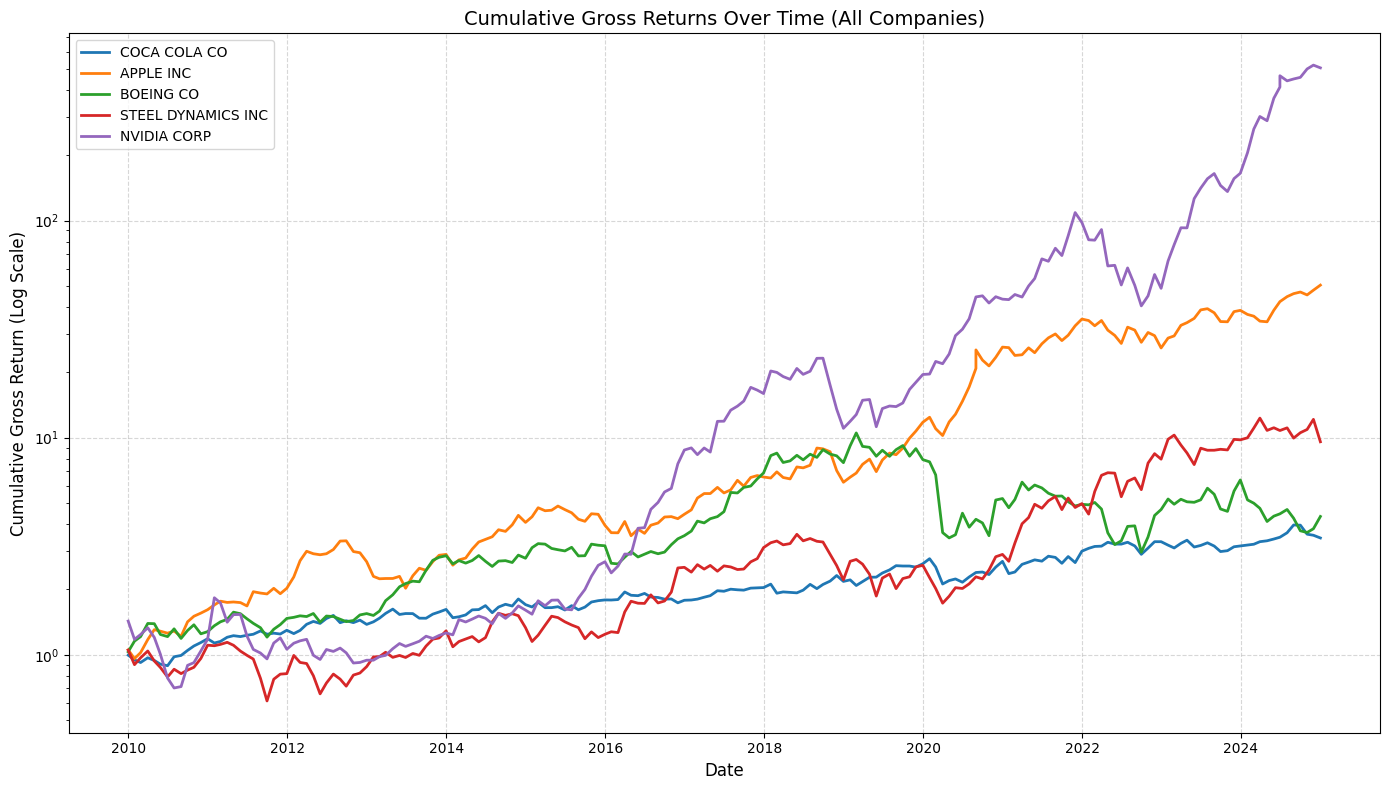

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

# Plot cumulative gross returns over time for each company
for company in companies:
    company_df = df[df['comnam'] == company].sort_values('date')
    plt.plot(company_df['date'], company_df['cum_gross_ret'], label=company, linewidth=2)

plt.title("Cumulative Gross Returns Over Time (All Companies)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Cumulative Gross Return (Value of $1 Invested)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)

# Using a logarithmic scale due to wide scale variations
plt.yscale('log')
plt.ylabel("Cumulative Gross Return (Log Scale)", fontsize=12)

plt.tight_layout()
plt.show()

### Reshaping Data: Long Format to Stock-by-Stock Wide Format
To make it easier to perform side-by-side stock analysis, we can pivot our main dataset so that each column represents an individual stock's metric (such as Cleaned Price, Monthly Return, or Cumulative Return) indexed by Date.

In [22]:
import pandas as pd

# Pivot using pivot_table to handle duplicate index entries by taking the average/first value
prices_wide = df.pivot_table(index='date', columns='comnam', values='prc_cleaned', aggfunc='first')
print("--- Cleaned Stock Prices (Wide Format) ---")
display(prices_wide.head())

# Pivot Cleaned Monthly Returns
returns_wide = df.pivot_table(index='date', columns='comnam', values='ret_cleaned', aggfunc='first')
print("\n--- Monthly Returns (Wide Format) ---")
display(returns_wide.head())

# Pivot Cumulative Gross Returns
cum_returns_wide = df.pivot_table(index='date', columns='comnam', values='cum_gross_ret', aggfunc='first')
print("\n--- Cumulative Gross Returns (Wide Format) ---")
display(cum_returns_wide.head())

--- Cleaned Stock Prices (Wide Format) ---


comnam,APPLE INC,BOEING CO,COCA COLA CO,NVIDIA CORP,STEEL DYNAMICS INC
date,,,,,
2009-12-31,210.73199,54.13,57.00,18.68,17.72
2010-01-29,192.06300,60.60,54.25,15.39,15.18
2010-02-26,204.62000,63.16,52.72,16.20,16.33
2010-03-31,235.00000,72.61,55.00,17.40,17.47
2010-04-30,261.09000,72.43,53.45,15.71,15.72



--- Monthly Returns (Wide Format) ---


comnam,APPLE INC,BOEING CO,COCA COLA CO,NVIDIA CORP,STEEL DYNAMICS INC
date,,,,,
2009-12-31,0.054134,0.032818,-0.003497,0.430322,0.051714
2010-01-29,-0.088591,0.119527,-0.048246,-0.176124,-0.143341
2010-02-26,0.065380,0.049175,-0.028203,0.052632,0.075758
2010-03-31,0.148470,0.149620,0.051593,0.074074,0.074403
2010-04-30,0.111021,-0.002479,-0.028182,-0.097126,-0.100172



--- Cumulative Gross Returns (Wide Format) ---


comnam,APPLE INC,BOEING CO,COCA COLA CO,NVIDIA CORP,STEEL DYNAMICS INC
date,,,,,
2009-12-31,1.054134,1.032818,0.996503,1.430322,1.051714
2010-01-29,0.960747,1.156268,0.948426,1.178408,0.900960
2010-02-26,1.023561,1.213127,0.921677,1.240430,0.969215
2010-03-31,1.175529,1.394635,0.969229,1.332314,1.041328
2010-04-30,1.306037,1.391178,0.941915,1.202911,0.937016


### Plotting Wide-Format Restructured Data
We can easily plot the structured wide-format dataframes we just created. Using the wide-format DataFrames allows us to plot all stock trajectories simultaneously with a simple, clean pandas plot command.

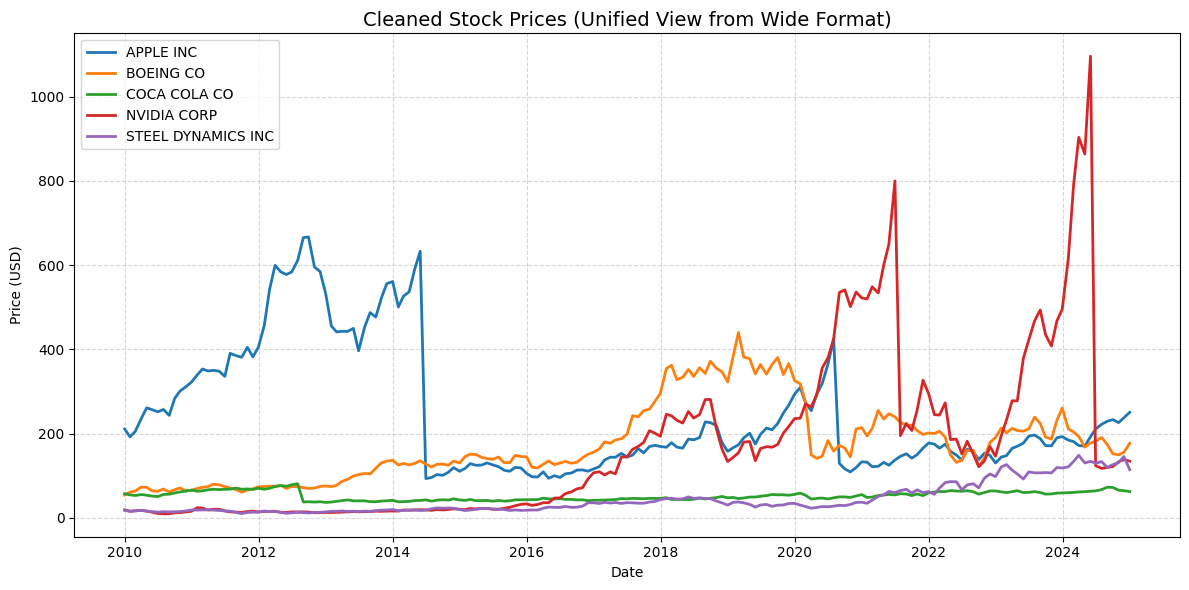

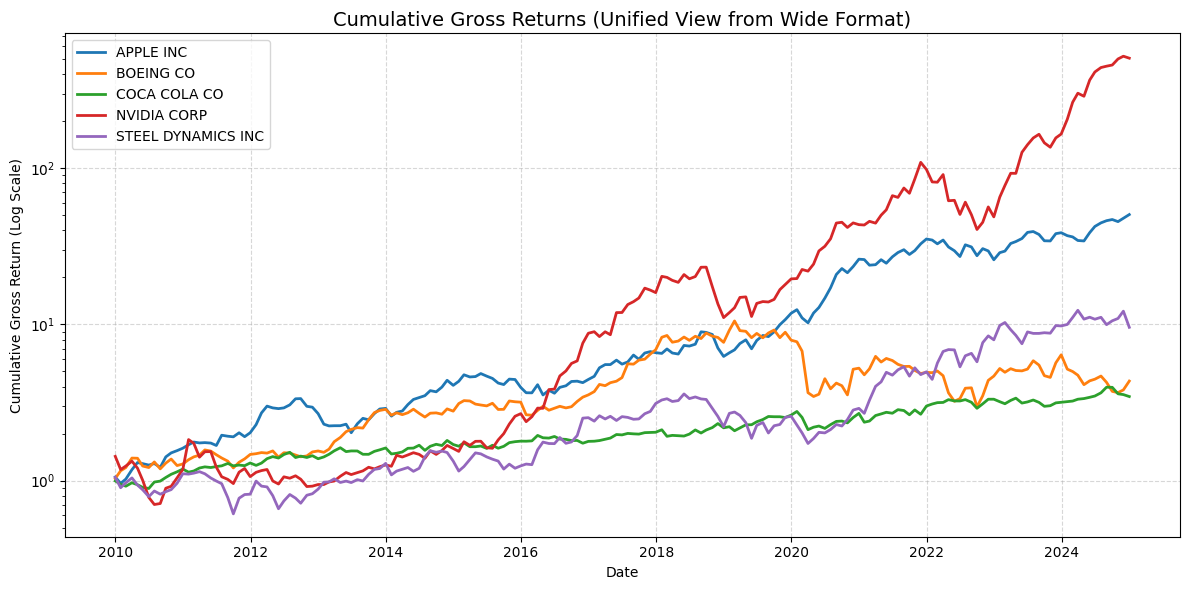

In [23]:
import matplotlib.pyplot as plt

# 1. Plot Combined Stock Prices
plt.figure(figsize=(12, 6))
for col in prices_wide.columns:
    plt.plot(prices_wide.index, prices_wide[col], label=col, linewidth=2)
plt.title("Cleaned Stock Prices (Unified View from Wide Format)", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Plot Combined Cumulative Gross Returns
plt.figure(figsize=(12, 6))
for col in cum_returns_wide.columns:
    plt.plot(cum_returns_wide.index, cum_returns_wide[col], label=col, linewidth=2)
plt.title("Cumulative Gross Returns (Unified View from Wide Format)", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Cumulative Gross Return (Log Scale)")
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Cumulative Gross Returns Per Share Value (Individual Plots)
We will plot the cumulative gross returns (the growth of a $1 investment per share) for each individual company on separate subplots to clearly analyze each stock's performance.

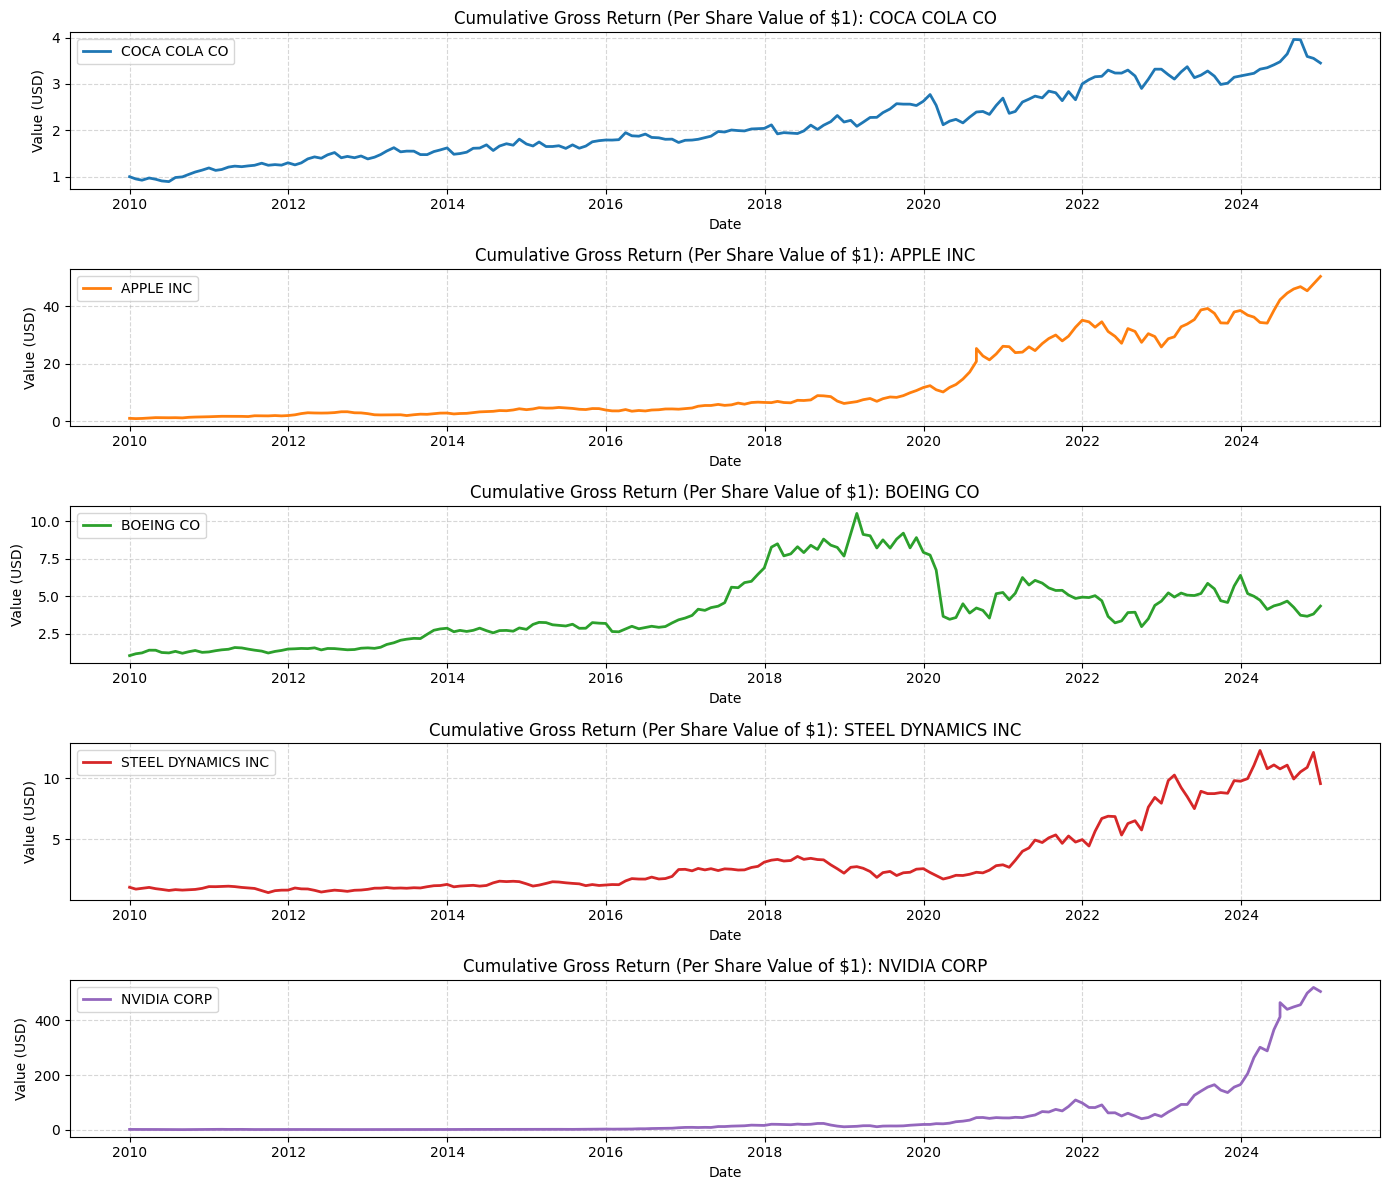

In [24]:
import matplotlib.pyplot as plt

# Create individual subplots for each company's cumulative gross return
plt.figure(figsize=(14, 12))

for i, company in enumerate(companies, 1):
    company_df = df[df['comnam'] == company].sort_values('date')

    plt.subplot(len(companies), 1, i)
    plt.plot(company_df['date'], company_df['cum_gross_ret'], label=company, color=f'C{i-1}', linewidth=2)
    plt.title(f"Cumulative Gross Return (Per Share Value of $1): {company}")
    plt.xlabel("Date")
    plt.ylabel("Value (USD)")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

### Merged Cumulative Gross Returns (Dollar Valuation Growth)
We will plot the cumulative gross returns for all five companies on a single, unified chart. This displays how a $1 investment per share grows in dollar valuation over the historical period.

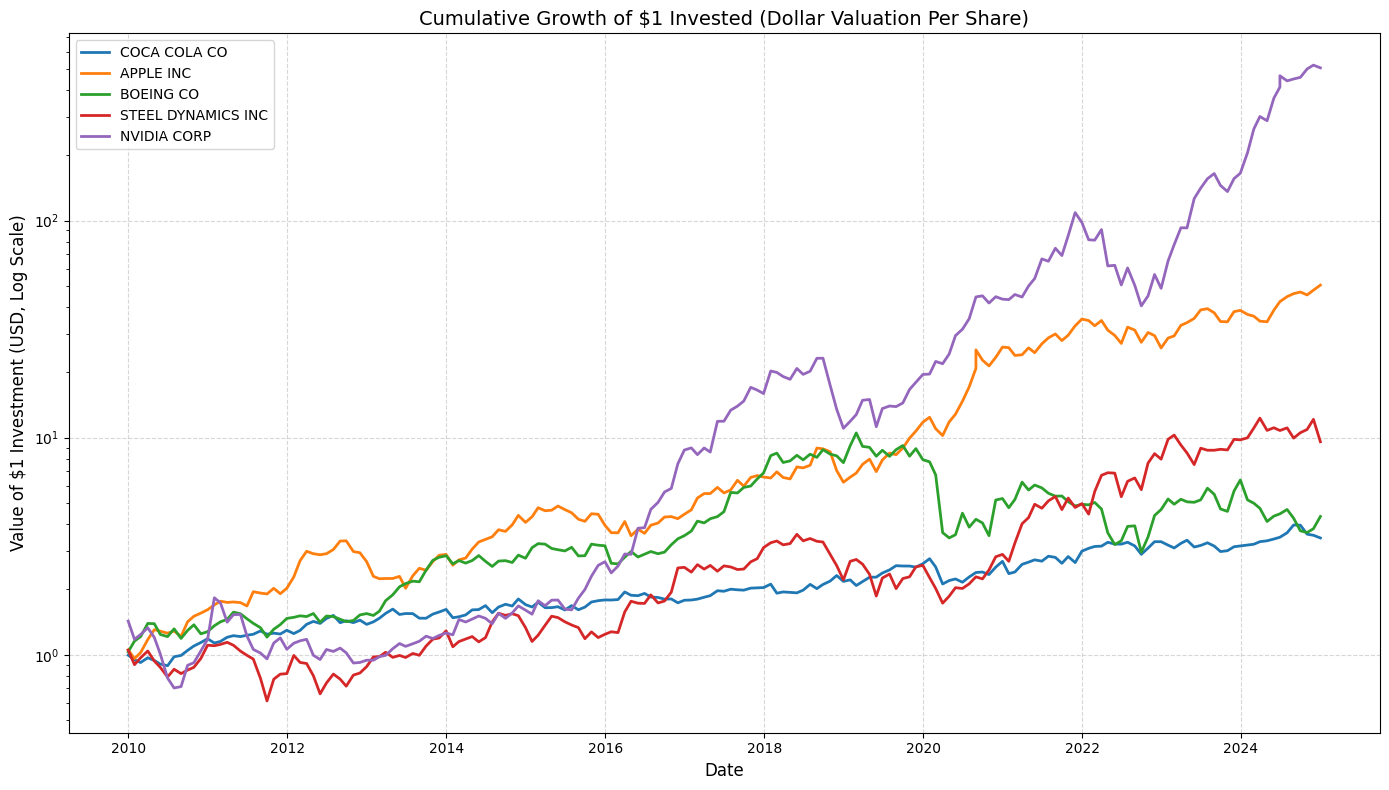

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

# Plot the cumulative gross return for all companies on the same chart
for company in companies:
    company_df = df[df['comnam'] == company].sort_values('date')
    plt.plot(company_df['date'], company_df['cum_gross_ret'], label=company, linewidth=2)

plt.title("Cumulative Growth of $1 Invested (Dollar Valuation Per Share)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Value of $1 Investment (USD)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)

# Using logarithmic scale to handle the wide span of performance (e.g., NVIDIA vs Others)
plt.yscale('log')
plt.ylabel("Value of $1 Investment (USD, Log Scale)", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')